<a href="https://colab.research.google.com/github/Firdaus2812/Solar-Tracker-PID/blob/main/BAB_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Simulasi PID diskrit sumbu X - Dual Axis Solar Tracker (ESP32)
# Kp, Ki, Kd, DEADBAND = hasil tuning penelitian; LDR awal & GAIN_MOTOR = nilai ilustrasi.
Kp, Ki, Kd = 0.5, 0.1, 0.5   # sumbu X
dt = 0.1                     # sampling time (s)
DEADBAND = 230               # batas toleransi error (ADC)
INT_LIMIT = 1000             # batas integral (anti-windup)
PWM_MIN, PWM_MAX = 60, 255   # contoh; samakan dengan .ino
ERR_MAX = 2500               # error maksimum (ADC)
GAIN_MOTOR = 1.2             # ilustrasi: laju turun error (ADC/s) per 1 PWM

LDR1, LDR2 = 2600.0, 1100.0  # posisi awal: cahaya lebih terang di LDR1
integral, e_prev, t, k = 0.0, None, 0.0, 0

print("  k |  t(s) |  LDR1 |  LDR2 |   e[k] |   P[k] |  I[k] |   D[k] |   u[k] | PWM")
while k < 400:
    e = LDR1 - LDR2                                  # (1) error
    if abs(e) < DEADBAND:                            # (2) deadband -> motor berhenti
        print(f"Error {e:.0f} < {DEADBAND}: motor berhenti pada t = {t:.1f} s")
        break
    if e_prev is None: e_prev = e
    integral = max(-INT_LIMIT, min(INT_LIMIT, integral + e * dt))   # (3) integral
    P, I, D = Kp * e, Ki * integral, Kd * (e - e_prev) / dt         # (4) P, I, D
    u = P + I + D                                    # (5) keluaran PID
    ratio = (min(abs(e), ERR_MAX) - DEADBAND) / (ERR_MAX - DEADBAND)
    pwm = int(PWM_MIN + ratio * (PWM_MAX - PWM_MIN))                # (6) skala ke PWM
    pwm = pwm if u > 0 else -pwm
    if k < 5 or k % 20 == 0:
        print(f"{k:3d} | {t:5.1f} | {LDR1:5.0f} | {LDR2:5.0f} | {e:6.0f} | {P:6.1f} | {I:5.1f} | {D:6.1f} | {u:6.1f} | {pwm:4d}")
    e_prev = e
    LDR1 -= GAIN_MOTOR * abs(pwm) * dt * (1 if u > 0 else -1) * 0.5   # panel bergerak -> LDR1 turun
    LDR2 += GAIN_MOTOR * abs(pwm) * dt * (1 if u > 0 else -1) * 0.5   # LDR2 naik
    t += dt; k += 1

  k |  t(s) |  LDR1 |  LDR2 |   e[k] |   P[k] |  I[k] |   D[k] |   u[k] | PWM
  0 |   0.0 |  2600 |  1100 |   1500 |  750.0 |  15.0 |    0.0 |  765.0 |  169
  1 |   0.1 |  2590 |  1110 |   1480 |  739.9 |  29.8 | -101.4 |  668.3 |  167
  2 |   0.2 |  2580 |  1120 |   1460 |  729.8 |  44.4 | -100.2 |  674.0 |  165
  3 |   0.3 |  2570 |  1130 |   1440 |  719.9 |  58.8 |  -99.0 |  679.7 |  163
  4 |   0.4 |  2560 |  1140 |   1420 |  710.2 |  73.0 |  -97.8 |  685.4 |  162
 20 |   2.0 |  2416 |  1284 |   1133 |  566.4 | 100.0 |  -82.8 |  583.6 |  137
 40 |   4.0 |  2267 |  1433 |    834 |  417.1 | 100.0 |  -67.8 |  449.3 |  111
 60 |   6.0 |  2146 |  1554 |    592 |  295.9 | 100.0 |  -55.2 |  340.7 |   91
 80 |   8.0 |  2047 |  1653 |    394 |  197.1 | 100.0 |  -44.4 |  252.7 |   74
100 |  10.0 |  1967 |  1733 |    234 |  116.9 | 100.0 |  -36.0 |  180.9 |   60
Error 227 < 230: motor berhenti pada t = 10.1 s


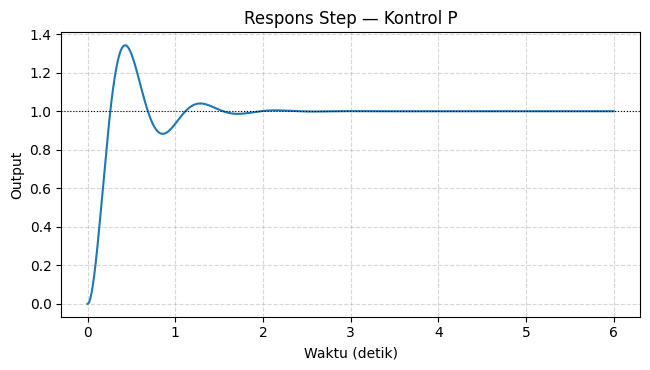

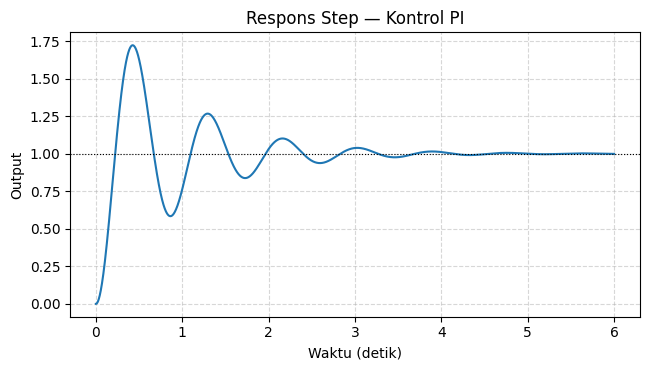

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Model Motor DC ilustratif: G(s) = K / [s(s+a)]
K, a = 30.0, 5.0
num_motor, den_motor = [K], [1, a, 0]
t = np.linspace(0, 6, 3000)

def closed_loop_step(num_c, den_c):
    num_L = np.polymul(num_c, num_motor)
    den_L = np.polymul(den_c, den_motor)
    n, d = len(num_L), len(den_L)
    num_T = num_L
    den_T = np.polyadd(np.pad(den_L, (max(0, n-d), 0)),
                        np.pad(num_L, (max(0, d-n), 0)))
    _, y = signal.step(signal.TransferFunction(num_T, den_T), T=t)
    return y

# Kontrol P
y_p = closed_loop_step([2.0], [1])

# Kontrol PI  (Kp=2, Ki=5)
y_pi = closed_loop_step([2.0, 5.0], [1, 0])

for y, title, fname in [(y_p, "Kontrol P", "output_p.png"),
                         (y_pi, "Kontrol PI", "output_pi.png")]:
    plt.figure(figsize=(6.6, 3.8))
    plt.plot(t, y)
    plt.axhline(1, linestyle=":", color="black", linewidth=0.8)
    plt.title(f"Respons Step — {title}")
    plt.xlabel("Waktu (detik)"); plt.ylabel("Output")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(fname, dpi=300)